# MedSAM2 fixed 2D plane

One stationary 2D box, taken from the reference frame's 3D bounding box, and one fixed axial plane, the center slice of that same bounding box. MedSAM2 segments that plane on every frame with the same box prompt, so the contour is free to move or vanish as the lesion drifts through the plane.

In [47]:
%reload_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Notebook lives in CLI-Demos; `src` is one level up (engines/ceus).
sys.path.insert(0, str(Path.cwd().parent))
sys.path.insert(0, str(Path.cwd() / "medsam2_function"))

## Choose a visit

Run the first cell to list every row, then set `CASE_IDX`.

In [48]:
import pandas as pd

MASTER_CSV = "/media/ahmed-el-kaffas/20TB-HDD/Yuanshan/3DMPUS/Motion_compensation_results/Motion Compensation Comparison 4 patients(MedSAM2).csv"

df = pd.read_csv(MASTER_CSV)
df[["Site", "Patient Number", "Visit", "Bolus"]]

,Site,Patient Number,Visit,Bolus
0,UCSD,P05,V01,CE1
1,UCSD,P05,V01,CE2
2,UCSD,P05,V02,CE1
3,UCSD,P05,V02,CE2
4,UCSD,P05,V03,CE1
5,UCSD,P05,V03,CE2
6,UCSD,P07,V01,CE1RUN2
7,UCSD,P07,V01,CE2
8,UCSD,P07,V02,CE01RUN2
9,UCSD,P07,V02,CE2


In [49]:
from case_files import find_bmode_file, find_ceus_file, find_voi_file

CASE_IDX = 0

row = df.iloc[CASE_IDX]
print(f"=== {row['Site']}-{row['Patient Number']}-{row['Visit']}-{row['Bolus']} ===")

bmode_path = find_bmode_file(row["Data Dir"], row["Visit"], row["Bolus"])
ceus_path = find_ceus_file(bmode_path)
voi_path = find_voi_file(row["Data Dir"], row["Visit"], row["Bolus"])
for name, p in (("bmode", bmode_path), ("ceus", ceus_path), ("voi", voi_path)):
    print(f"  {name:5s}: {os.path.basename(p)}")

=== UCSD-P05-V01-CE1 ===
  bmode: UCSD-P05-V01-CE1_11.24.01_mf_sip_capture_50_2_1_0_BMODE.nii
  ceus : UCSD-P05-V01-CE1_11.24.01_mf_sip_capture_50_2_1_0_CEUS.nii
  voi  : UCSD-P05-V01-CE1-MC_VOI.nii.gz


## Reference box and plane

The motion-compensation result is stored in the VOI file's header, so loading the VOI gives `seg_data.motion_compensation` with `reference_frame` and `reference_bbox` (the VOI's tight box plus the padding used when MC was run). The 2D prompt is that box's X/Y extent, and the plane is the middle of its Z extent. Set `Z_OVERRIDE` to use a different plane.

In [50]:
from src.entrypoints import seg_loading_step

seg_data = seg_loading_step("nifti", None, voi_path, ceus_path)     # the NIfTI loader does not use image_data
mc = seg_data.motion_compensation
assert mc is not None, "This VOI file has no motion_compensation header; run motion compensation first."

ref_frame = mc.reference_frame
bb = mc.reference_bbox

Z_OVERRIDE = None
z = int((bb.z_min + bb.z_max) // 2) if Z_OVERRIDE is None else Z_OVERRIDE
box_2d = [int(v) for v in (bb.x_min, bb.y_min, bb.x_max, bb.y_max)]      # [x_min, y_min, x_max, y_max] on the (Y, X) plane

print(f"reference frame = {ref_frame}")
print(f"3D bbox  X=[{bb.x_min}, {bb.x_max}]  Y=[{bb.y_min}, {bb.y_max}]  Z=[{bb.z_min}, {bb.z_max}]")
print(f"fixed plane z = {z}   2D box = {box_2d}")

reference frame = 10
3D bbox  X=[97.0, 180.0]  Y=[80.0, 136.0]  Z=[82.0, 156.0]
fixed plane z = 119   2D box = [97, 80, 180, 136]


## Pull the axial video

The reference frame is always included.

In [51]:
import numpy as np

from medsam2_axial_video import extract_axial_video

N_FRAMES = 100

import nibabel as nib

n_total = nib.load(bmode_path).shape[-1]
frame_indices = sorted(set(np.linspace(0, n_total - 1, N_FRAMES).round().astype(int).tolist()) | {ref_frame})

video = extract_axial_video(bmode_path, ceus_path, z, frame_indices=frame_indices)
assert seg_data.seg_mask.shape == nib.load(bmode_path).shape[:3], "VOI and B-mode are on different grids"
print(f"B-mode {video['bmode'].shape}  CEUS {video['ceus'].shape}  (T, H, W)")
print(f"frames {video['frame_indices']}")

B-mode (101, 218, 295)  CEUS (101, 218, 295)  (T, H, W)
frames [0, 5, 10, 11, 16, 21, 26, 32, 37, 42, 48, 53, 58, 63, 69, 74, 79, 85, 90, 95, 100, 106, 111, 116, 122, 127, 132, 137, 143, 148, 153, 158, 164, 169, 174, 180, 185, 190, 195, 201, 206, 211, 217, 222, 227, 232, 238, 243, 248, 254, 259, 264, 269, 275, 280, 285, 291, 296, 301, 306, 312, 317, 322, 328, 333, 338, 343, 349, 354, 359, 365, 370, 375, 380, 386, 391, 396, 401, 407, 412, 417, 423, 428, 433, 438, 444, 449, 454, 460, 465, 470, 475, 481, 486, 491, 497, 502, 507, 512, 518, 523]


## MedSAM2 on the fixed plane

Same fold-held-out checkpoint as the other notebooks. Each frame's B-mode plane gets the same `box_2d` prompt; there is no tracking and no use of the GT.

In [52]:
import time

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

from fold_checkpoints import checkpoint_for
from medsam2_viewer_base import run_medsam2_2d

model_cfg = "configs/sam2.1_hiera_t512.yaml"
checkpoint = os.environ.get("MEDSAM2_CHECKPOINT") or checkpoint_for(row["Site"], row["Patient Number"])
predictor = SAM2ImagePredictor(build_sam2(model_cfg, checkpoint, device="cuda"))

H, W = video["bmode"].shape[1:]
t0 = time.time()
masks = []
for plane in video["bmode"]:
    m = run_medsam2_2d(predictor, plane, box_2d, device="cuda")
    masks.append(np.zeros((H, W), bool) if m is None else m)
masks = np.stack(masks)
print(f"{len(masks)} frames in {time.time() - t0:.1f} s")
print("mask area (px):", masks.sum(axis=(1, 2)).tolist())

UCSD-P05: fold 4 (held out) -> fold_4.pt
101 frames in 0.6 s
mask area (px): [2860, 3686, 2843, 2842, 3051, 2610, 3735, 2848, 3752, 2972, 3117, 2615, 2657, 3102, 2946, 2993, 2863, 2621, 3146, 2985, 3040, 2988, 3128, 3790, 2704, 3047, 2914, 3123, 2944, 3724, 3130, 2946, 3076, 3187, 3077, 3008, 3101, 3156, 3167, 2938, 3053, 2903, 3164, 2999, 3147, 3057, 3080, 3808, 3076, 3846, 3111, 3097, 3119, 3001, 3133, 3142, 3072, 3074, 3068, 3125, 3696, 3115, 3038, 3760, 3055, 3014, 3022, 3073, 3089, 3089, 3097, 3023, 3097, 3093, 2987, 3088, 2701, 3078, 3028, 2988, 3085, 3067, 3052, 2950, 3092, 2943, 3028, 3098, 3633, 3082, 2988, 3107, 3004, 3736, 2970, 3084, 2745, 3063, 3703, 3094, 2968]


## MedSAM2 on the motion-compensated plane

Same frames and checkpoint, but the prompt follows the lesion: on each frame the plane is the middle of that frame's **tracked** 3D box (`tracked_bboxes[t]`) and the 2D box is that tracked box's X/Y extent. This is the `sam2_2d_mc` variant from the batch notebook. The fixed variant above keeps one box and one plane for every frame.

In [53]:
tracked = mc.tracked_bboxes
n_z = seg_data.seg_mask.shape[2]
frames_t = video["frame_indices"]

z_mc = [int(np.clip((tracked[t].z_min + tracked[t].z_max) // 2, 0, n_z - 1)) for t in frames_t]
boxes_mc = [[int(v) for v in (tracked[t].x_min, tracked[t].y_min, tracked[t].x_max, tracked[t].y_max)]
            for t in frames_t]

# the plane differs per frame, so pull them one at a time
planes = [extract_axial_video(bmode_path, ceus_path, zt, frame_indices=[t]) for zt, t in zip(z_mc, frames_t)]
video_mc = {key: np.concatenate([p[key] for p in planes]) for key in ("bmode", "ceus")}

masks_mc = []
for plane, box in zip(video_mc["bmode"], boxes_mc):
    m = run_medsam2_2d(predictor, plane, box, device="cuda")
    masks_mc.append(np.zeros((H, W), bool) if m is None else m)
masks_mc = np.stack(masks_mc)

print("z (fixed):", z, "  z (mc):", z_mc)
print("mask area fixed (px):", masks.sum(axis=(1, 2)).tolist())
print("mask area mc    (px):", masks_mc.sum(axis=(1, 2)).tolist())

z (fixed): 119   z (mc): [119, 132, 119, 120, 133, 118, 129, 120, 128, 123, 131, 120, 123, 128, 123, 125, 119, 120, 128, 119, 125, 119, 127, 132, 119, 133, 123, 133, 119, 132, 127, 126, 133, 128, 133, 124, 129, 125, 132, 122, 133, 121, 132, 123, 130, 126, 127, 133, 125, 132, 126, 128, 133, 122, 133, 127, 129, 133, 125, 129, 124, 129, 127, 133, 126, 133, 123, 127, 130, 122, 133, 120, 130, 125, 121, 133, 121, 133, 120, 130, 124, 123, 133, 121, 128, 121, 132, 127, 121, 130, 123, 130, 123, 131, 124, 133, 123, 126, 125, 131, 122]
mask area fixed (px): [2860, 3686, 2843, 2842, 3051, 2610, 3735, 2848, 3752, 2972, 3117, 2615, 2657, 3102, 2946, 2993, 2863, 2621, 3146, 2985, 3040, 2988, 3128, 3790, 2704, 3047, 2914, 3123, 2944, 3724, 3130, 2946, 3076, 3187, 3077, 3008, 3101, 3156, 3167, 2938, 3053, 2903, 3164, 2999, 3147, 3057, 3080, 3808, 3076, 3846, 3111, 3097, 3119, 3001, 3133, 3142, 3072, 3074, 3068, 3125, 3696, 3115, 3038, 3760, 3055, 3014, 3022, 3073, 3089, 3089, 3097, 3023, 3097, 3093, 29

## Video: fixed plane (top) vs motion-compensated plane (bottom)

Each row is B-mode (left) and CEUS (right). Top row: the stationary box and plane. Bottom row: the tracked box and plane, which move with the lesion, so the box and the slice number change per frame. Cyan dashed = prompt box, lime = MedSAM2's mask, red = the reference VOI at the reference frame only (the one frame where it is a ground-truth outline).

`DENOISE` is display only: `None` (raw, windowed to the `LOW_PCT`/`HIGH_PCT` percentiles of each stack), or `"none"`, `"nlm"`, `"wavelet"`, `"nlm_then_wavelet"` from `enhance_bmode_noise`, which denoises each frame and then does its own per-frame percentile stretch. MedSAM2 above always sees the raw B-mode.

In [54]:
import contextlib
import io

import matplotlib.pyplot as plt
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle

from medsam2_viewer_base import enhance_bmode_noise

DENOISE = "nlm"          # None | "none" | "nlm" | "wavelet" | "nlm_then_wavelet"
LOW_PCT, HIGH_PCT = 1, 99.5
INTERVAL_MS = 250

ref_pos = video["frame_indices"].index(ref_frame)
ref_plane = (seg_data.seg_mask[:, :, z] > 0).T                       # (Y, X)

def prepare(stack):
    """Return (frames, vmin, vmax) ready for imshow."""
    if DENOISE is None:
        lo, hi = np.percentile(stack, [LOW_PCT, HIGH_PCT])
        return stack, lo, hi
    with contextlib.redirect_stdout(io.StringIO()):      # drop the per-frame timing prints
        out = np.stack([enhance_bmode_noise(f, LOW_PCT, HIGH_PCT, method=DENOISE) for f in stack])
    return out, 0, 255

# row -> (label, video, masks, per-frame boxes, per-frame z)
rows = {
    "fixed": ("Fixed plane", video, masks, [box_2d] * len(masks), [z] * len(masks)),
    "mc":    ("MC plane", video_mc, masks_mc, boxes_mc, z_mc),
}
prepared = {k: {m: prepare(v[m]) for m in ("bmode", "ceus")} for k, (_, v, *_rest) in rows.items()}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
ims, rects = {}, {}
for r, (key, (label, v, _, boxes, _)) in enumerate(rows.items()):
    for c, (mod, name) in enumerate((("bmode", "B-mode"), ("ceus", "CEUS"))):
        ax = axes[r, c]
        frames, lo, hi = prepared[key][mod]
        ims[key, mod] = ax.imshow(frames[0], cmap="gray", vmin=lo, vmax=hi)
        x0, y0, x1, y1 = boxes[0]
        rects[key, mod] = ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="cyan", ls="--", lw=1))
        ax.axis("off")
title = fig.suptitle("")
contours = []

def update(i):
    for cs in contours:
        cs.remove()
    contours.clear()
    for r, (key, (label, v, msk, boxes, zs)) in enumerate(rows.items()):
        x0, y0, x1, y1 = boxes[i]
        ref = (seg_data.seg_mask[:, :, zs[i]] > 0).T if i == ref_pos else None
        for c, (mod, name) in enumerate((("bmode", "B-mode"), ("ceus", "CEUS"))):
            ax = axes[r, c]
            ims[key, mod].set_data(prepared[key][mod][0][i])
            rects[key, mod].set_bounds(x0, y0, x1 - x0, y1 - y0)
            for mask, color in ((msk[i], "lime"), (ref, "red")):
                if mask is not None and mask.any():
                    contours.append(ax.contour(mask, levels=[0.5], colors=color, linewidths=1.2))
            ax.set_title(f"{name} - {label}  z={zs[i]}  area={int(msk[i].sum())} px", fontsize=10)
    title.set_text(f"t={video['frame_indices'][i]}  denoise={DENOISE}" + ("   [reference frame]" if i == ref_pos else ""))
    return list(ims.values())

anim = FuncAnimation(fig, update, frames=len(video["frame_indices"]), interval=INTERVAL_MS, blit=False)
plt.close(fig)
display(HTML(anim.to_jshtml()))

## TIC on the fixed plane (2D only)

The TIC is the framework's `tic` curve (`CurvesAnalysis`, via `medsam2_tic.py`) over the MedSAM2 mask on the fixed plane, and the log-normal fit is `curve_quantification_step` with `lognormal_fit_full`, the same functions as the 3D TIC cells in MedSam2_inference. The framework assumes consecutive frames, so this pulls and segments **every** frame, not the `N_FRAMES` subset shown above.

In [59]:
from tqdm import tqdm

from src.data_objs.image import UltrasoundImage
from src.data_objs.seg import CeusSeg

from medsam2_tic import tic_analysis

full = extract_axial_video(bmode_path, ceus_path, z, frame_indices=list(range(n_total)))

masks_full = []
mask_mc = []
for plane in tqdm(full["bmode"], desc="MedSAM2 [fixed plane]"):
    m = run_medsam2_2d(predictor, plane, box_2d, device="cuda")
    masks_full.append(np.zeros((H, W), bool) if m is None else m)
masks_full = np.stack(masks_full)

# (T, H, W) CEUS planes as the framework's "2D + time" image, frame rate as the NIfTI loader sets it
image_2d = UltrasoundImage(ceus_path)
image_2d.pixel_data = image_2d.intensities_for_analysis = full["ceus"]
image_2d.pixdim = full["spacing_mm_yx"]
image_2d.frame_rate = 1.0 / nib.load(ceus_path).header.get_zooms()[3]
seg_2d = CeusSeg()
seg_2d.seg_name = "medsam2_fixed_plane"

analysis_2d = tic_analysis(image_2d, seg_2d, lambda f: masks_full[f], desc="TIC [fixed plane]")
tic_2d = np.asarray(analysis_2d.curves[0]["TIC"], dtype=float)
print(f"{len(tic_2d)} frames  min {np.nanmin(tic_2d):.2f}  max {np.nanmax(tic_2d):.2f}  empty-mask frames: {int((masks_full.sum(axis=(1, 2)) == 0).sum())}")

TIC [fixed plane]: 100%|██████████| 524/524 [00:00<00:00, 38847.82it/s]


524 frames  min 20.81  max 105.26  empty-mask frames: 0


In [60]:
# ── TIC on the motion-compensated plane ───────────────────────────────────────
tracked = mc.tracked_bboxes
assert len(tracked) == n_total, "expected one tracked box per frame"

z_mc_all = [int(np.clip((bb.z_min + bb.z_max) // 2, 0, n_z - 1)) for bb in tracked]
boxes_mc_all = [[int(v) for v in (bb.x_min, bb.y_min, bb.x_max, bb.y_max)] for bb in tracked]

# one plane per frame, at that frame's tracked z (open each NIfTI once)
bmode_img, ceus_img = nib.load(bmode_path), nib.load(ceus_path)
bmode_mc = np.stack([np.asarray(bmode_img.dataobj[:, :, zt, t], dtype=np.uint8).T for t, zt in enumerate(z_mc_all)])
ceus_mc  = np.stack([np.asarray(ceus_img.dataobj[:, :, zt, t], dtype=np.uint8).T for t, zt in enumerate(z_mc_all)])

masks_mc_all = []
for plane, box in tqdm(zip(bmode_mc, boxes_mc_all), total=n_total, desc="MedSAM2 [MC plane]"):
    m = run_medsam2_2d(predictor, plane, box, device="cuda")
    masks_mc_all.append(np.zeros((H, W), bool) if m is None else m)
masks_mc_all = np.stack(masks_mc_all)

# same framework path as the fixed-plane TIC, on the MC planes
image_2d_mc = UltrasoundImage(ceus_path)
image_2d_mc.pixel_data = image_2d_mc.intensities_for_analysis = ceus_mc
image_2d_mc.pixdim = full["spacing_mm_yx"]
image_2d_mc.frame_rate = image_2d.frame_rate

analysis_2d_mc = tic_analysis(image_2d_mc, seg_2d, lambda f: masks_mc_all[f], desc="TIC [MC plane]")
quant_2d_mc = lognormal_quantification(analysis_2d_mc)
fit_2d_mc = fitted_curve(analysis_2d_mc, quant_2d_mc)
tic_2d_mc = np.asarray(analysis_2d_mc.curves[0]["TIC"], dtype=float)

TIC [MC plane]: 100%|██████████| 524/524 [00:00<00:00, 34018.22it/s]


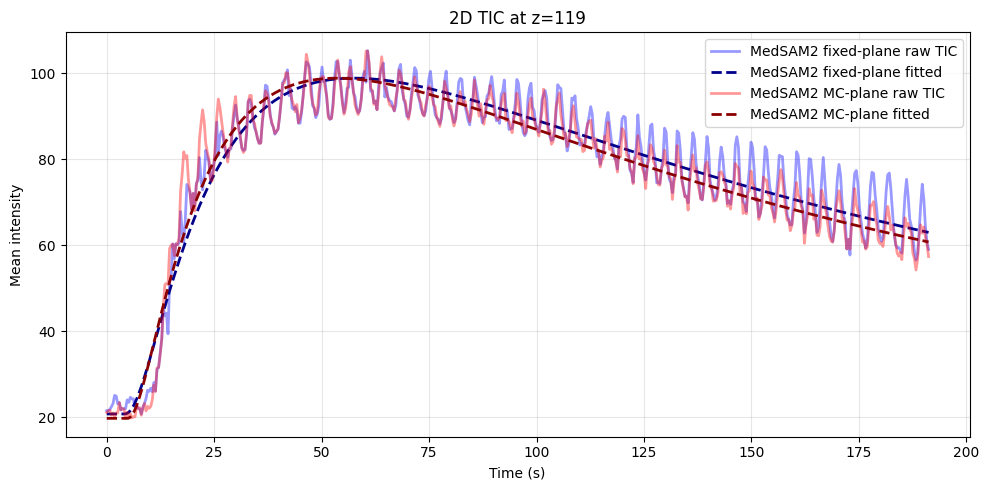

r2               0.9232
roughness        2.8618
snr            121.8843
auc          22347.3337
pe              78.0724
tp              53.7428
mtt            360.6157
t0               3.7246
wash_in          0.5615
wash_out        -0.0974
r2               0.9383
roughness        2.4032
snr            192.5970
auc          22390.3191
pe              79.0843
tp              49.0372
mtt            377.5219
t0               4.4833
wash_in          0.6085
wash_out        -0.1067


In [61]:
from medsam2_tic import fit_quality, fitted_curve, lognormal_quantification

quant_2d = lognormal_quantification(analysis_2d)
fit_2d = fitted_curve(analysis_2d, quant_2d)
time_2d = analysis_2d.time_arr

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(time_2d, tic_2d, color="blue", linewidth=2, alpha=0.4, label="MedSAM2 fixed-plane raw TIC")
ax.plot(time_2d, fit_2d, color="darkblue", linewidth=2, linestyle="--", label="MedSAM2 fixed-plane fitted")
ax.plot(time_2d, tic_2d_mc, color="red", linewidth=2, alpha=0.4, label="MedSAM2 MC-plane raw TIC")
ax.plot(time_2d, fit_2d_mc, color="darkred", linewidth=2, linestyle="--", label="MedSAM2 MC-plane fitted")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Mean intensity")
ax.set_title(f"2D TIC at z={z}")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

q_fix, q_mc = fit_quality(analysis_2d, quant_2d), fit_quality(analysis_2d_mc, quant_2d_mc)
for key, val in fit_quality(analysis_2d, quant_2d).items():
    print(f"{key:<10} {val:>12.4f}")
for key, val in fit_quality(analysis_2d_mc, quant_2d_mc).items():
    print(f"{key:<10} {val:>12.4f}")